In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

# Define paths
model_path = r"C:\Users\rauna\OneDrive\Desktop\MLProject\models"
data_path = r"C:\Users\rauna\OneDrive\Desktop\MLProject\data"

# Load trained models
models = {
    'Dummy Classifier': joblib.load(os.path.join(model_path, 'baseline.pkl')),
    'Logistic Regression': joblib.load(os.path.join(model_path, 'logistic_regression.pkl')),
    'Decision Tree': joblib.load(os.path.join(model_path, 'decision_tree.pkl')),
    'Random Forest': joblib.load(os.path.join(model_path, 'random_forest.pkl')),
    'KNN': joblib.load(os.path.join(model_path, 'knn.pkl')),
    'SVM': joblib.load(os.path.join(model_path, 'svm.pkl'))
}

print("All trained models loaded successfully.")
print("Number of models:", len(models))


All trained models loaded successfully.
Number of models: 6


In [4]:

# Load test dataset
test_df = pd.read_csv(
    os.path.join(data_path, 'test_dataset.csv')
)

# Separate features and actual target
feature_cols = [
    'Recency',
    'Frequency',
    'Monetary',
    'AverageOrderValue',
    'ProductDiversity',
    'AvgItemsPerOrder'
]

X_test = test_df[feature_cols]
y_test = test_df['RepeatPurchase_90D']

print("Test dataset shape:", test_df.shape)
print("Test features:", X_test.shape)
print("Actual target:", y_test.shape)

print("\nActual target distribution:")
print(y_test.value_counts())


Test dataset shape: (1057, 7)
Test features: (1057, 6)
Actual target: (1057,)

Actual target distribution:
RepeatPurchase_90D
0    599
1    458
Name: count, dtype: int64


In [6]:

# Store predictions from each model
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

print("Predictions generated successfully.")

# Display a sample comparison
prediction_df = pd.DataFrame({
    'Actual': y_test.values,
    **predictions
})

display(prediction_df.head(10))


Predictions generated successfully.


,Actual,Dummy Classifier,Logistic Regression,Decision Tree,Random Forest,KNN,SVM
0,1,0,0,0,0,0,0
1,0,0,1,0,1,1,1
2,0,0,0,1,1,1,0
3,1,0,1,0,1,1,1
4,0,0,0,1,0,0,0
5,0,0,0,0,0,0,0
6,1,0,0,1,1,1,0
7,0,0,0,0,0,0,0
8,0,0,0,0,0,0,0
9,0,0,1,0,0,0,1


In [8]:

from sklearn.metrics import accuracy_score

accuracy_results = {}

for name, y_pred in predictions.items():
    accuracy = accuracy_score(y_test, y_pred)
    accuracy_results[name] = accuracy

accuracy_df = pd.DataFrame({
    'Model': accuracy_results.keys(),
    'Accuracy': accuracy_results.values()
})

accuracy_df = accuracy_df.sort_values(
    by='Accuracy',
    ascending=False
).reset_index(drop=True)

display(accuracy_df)


,Model,Accuracy
0,Random Forest,0.735099
1,Logistic Regression,0.726585
2,SVM,0.725639
3,KNN,0.700095
4,Decision Tree,0.638600
5,Dummy Classifier,0.566698


In [10]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

classification_results = []

for name, y_pred in predictions.items():

    classification_results.append({
        'Model': name,
        'Precision': precision_score(
            y_test, y_pred, zero_division=0
        ),
        'Recall': recall_score(
            y_test, y_pred, zero_division=0
        ),
        'F1-Score': f1_score(
            y_test, y_pred, zero_division=0
        )
    })

classification_df = pd.DataFrame(classification_results)

display(
    classification_df.sort_values(
        by='F1-Score',
        ascending=False
    ).reset_index(drop=True)
)


,Model,Precision,Recall,F1-Score
0,Random Forest,0.711905,0.652838,0.681093
1,Logistic Regression,0.697892,0.650655,0.673446
2,SVM,0.704878,0.631004,0.665899
3,KNN,0.664336,0.622271,0.642616
4,Decision Tree,0.584071,0.576419,0.580220
5,Dummy Classifier,0.000000,0.000000,0.000000


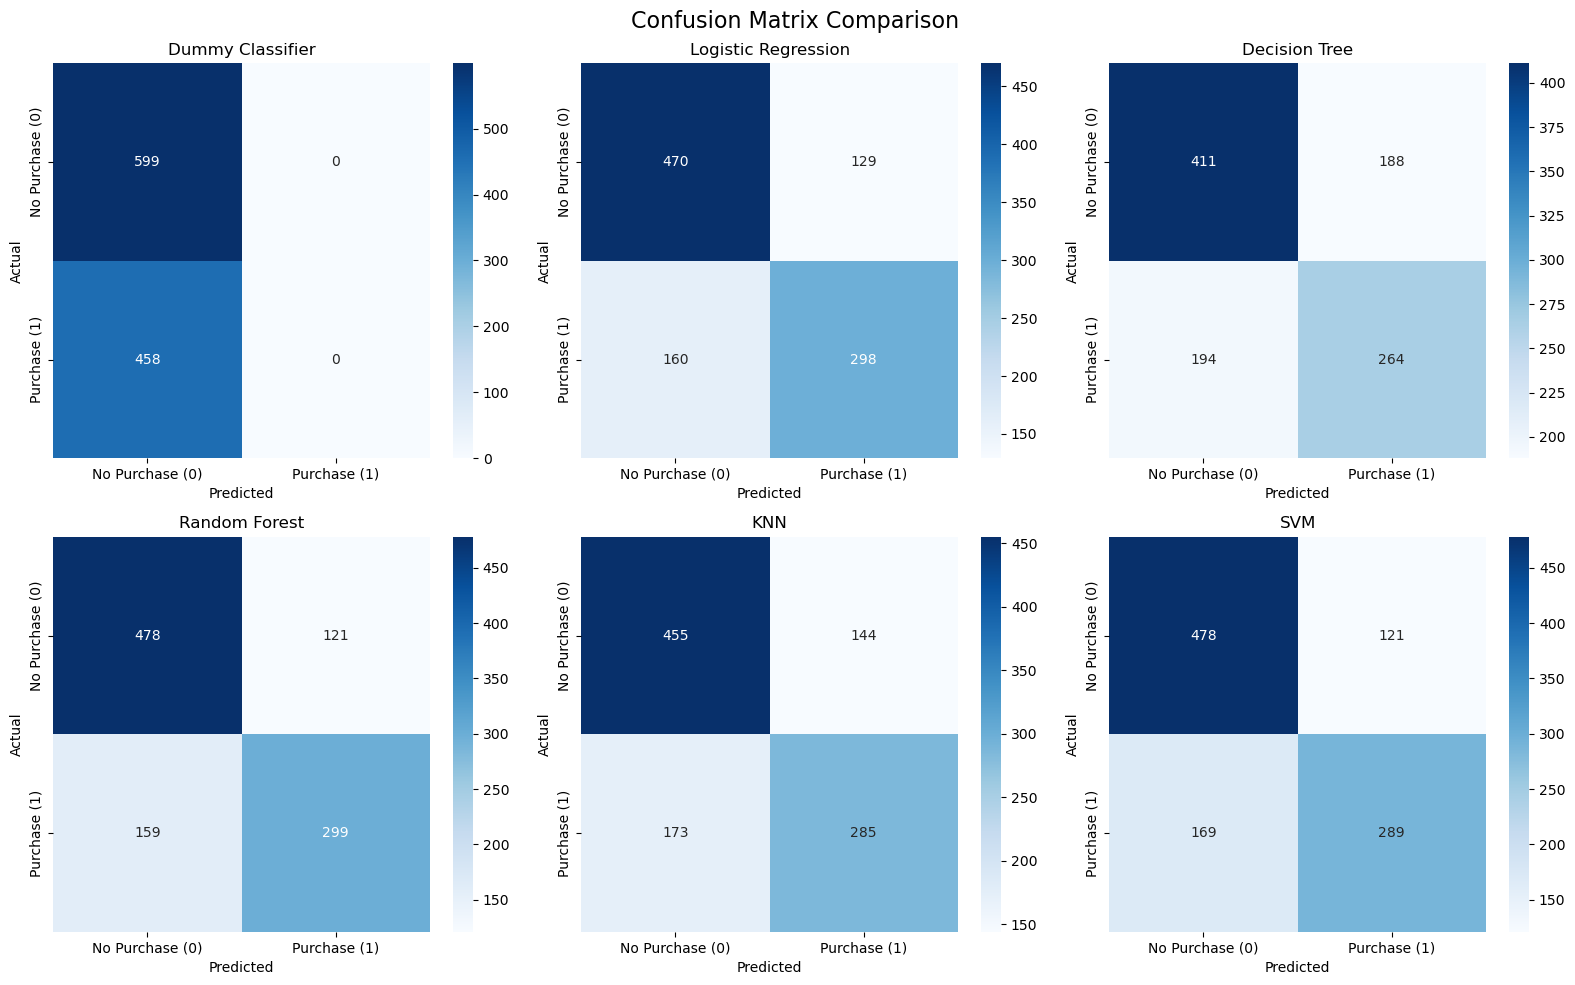

In [12]:

from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, (name, y_pred) in enumerate(predictions.items()):

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['No Purchase (0)', 'Purchase (1)'],
        yticklabels=['No Purchase (0)', 'Purchase (1)'],
        ax=axes[i]
    )

    axes[i].set_title(name)
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('Actual')

plt.suptitle('Confusion Matrix Comparison', fontsize=16)
plt.tight_layout()
plt.show()


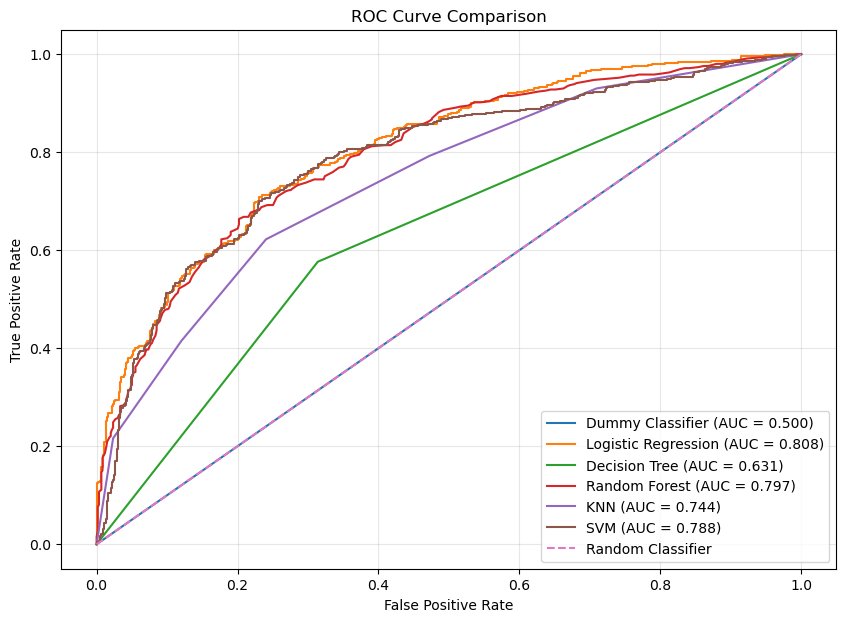

ROC-AUC Scores:


,Model,ROC-AUC
1,Logistic Regression,0.807583
3,Random Forest,0.796836
5,SVM,0.788472
4,KNN,0.744097
2,Decision Tree,0.631281
0,Dummy Classifier,0.500000


In [14]:

from sklearn.metrics import roc_curve, roc_auc_score

roc_results = {}

plt.figure(figsize=(10, 7))

for name, model in models.items():

    if hasattr(model, 'predict_proba'):
        y_scores = model.predict_proba(X_test)[:, 1]

    elif hasattr(model, 'decision_function'):
        y_scores = model.decision_function(X_test)

    else:
        continue

    auc_score = roc_auc_score(y_test, y_scores)
    fpr, tpr, thresholds = roc_curve(y_test, y_scores)

    roc_results[name] = auc_score

    plt.plot(
        fpr,
        tpr,
        label=f'{name} (AUC = {auc_score:.3f})'
    )

# Random classifier reference line
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("ROC-AUC Scores:")
display(
    pd.DataFrame(
        roc_results.items(),
        columns=['Model', 'ROC-AUC']
    ).sort_values('ROC-AUC', ascending=False)
)


In [16]:

# Combine all evaluation metrics
model_comparison = accuracy_df.merge(
    classification_df,
    on='Model'
)

# Add ROC-AUC scores
roc_df = pd.DataFrame(
    roc_results.items(),
    columns=['Model', 'ROC-AUC']
)

model_comparison = model_comparison.merge(
    roc_df,
    on='Model',
    how='left'
)

# Sort models by F1-score
model_comparison = model_comparison.sort_values(
    by='F1-Score',
    ascending=False
).reset_index(drop=True)

display(model_comparison.round(4))


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.7351,0.7119,0.6528,0.6811,0.7968
1,Logistic Regression,0.7266,0.6979,0.6507,0.6734,0.8076
2,SVM,0.7256,0.7049,0.6310,0.6659,0.7885
3,KNN,0.7001,0.6643,0.6223,0.6426,0.7441
4,Decision Tree,0.6386,0.5841,0.5764,0.5802,0.6313
5,Dummy Classifier,0.5667,0.0000,0.0000,0.0000,0.5000


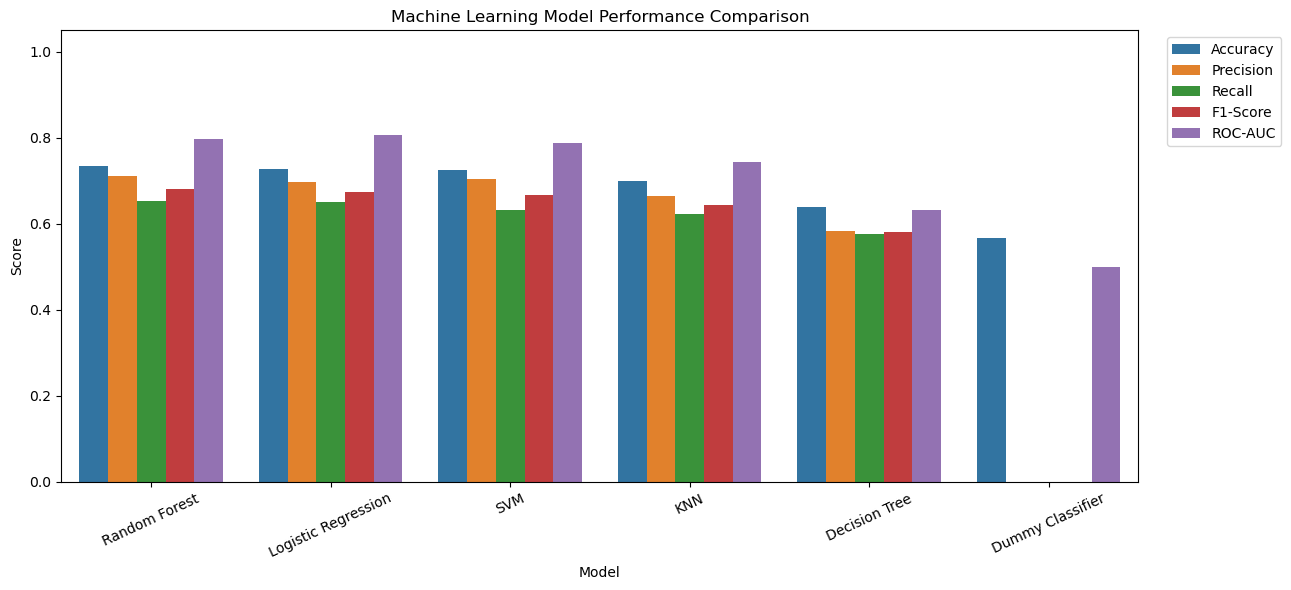

In [18]:

metrics = [
    'Accuracy',
    'Precision',
    'Recall',
    'F1-Score',
    'ROC-AUC'
]

plot_data = model_comparison.melt(
    id_vars='Model',
    value_vars=metrics,
    var_name='Metric',
    value_name='Score'
)

plt.figure(figsize=(13, 6))

sns.barplot(
    data=plot_data,
    x='Model',
    y='Score',
    hue='Metric'
)

plt.title('Machine Learning Model Performance Comparison')
plt.ylabel('Score')
plt.xlabel('Model')
plt.ylim(0, 1.05)
plt.xticks(rotation=25)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


In [20]:

from sklearn.metrics import classification_report

for name, y_pred in predictions.items():

    print(f"\n{'='*55}")
    print(f"MODEL: {name}")
    print('='*55)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=['No Repeat Purchase', 'Repeat Purchase'],
            zero_division=0
        )
    )



MODEL: Dummy Classifier
                    precision    recall  f1-score   support

No Repeat Purchase       0.57      1.00      0.72       599
   Repeat Purchase       0.00      0.00      0.00       458

          accuracy                           0.57      1057
         macro avg       0.28      0.50      0.36      1057
      weighted avg       0.32      0.57      0.41      1057


MODEL: Logistic Regression
                    precision    recall  f1-score   support

No Repeat Purchase       0.75      0.78      0.76       599
   Repeat Purchase       0.70      0.65      0.67       458

          accuracy                           0.73      1057
         macro avg       0.72      0.72      0.72      1057
      weighted avg       0.73      0.73      0.73      1057


MODEL: Decision Tree
                    precision    recall  f1-score   support

No Repeat Purchase       0.68      0.69      0.68       599
   Repeat Purchase       0.58      0.58      0.58       458

          accurac

In [24]:
# Extract feature importance from the trained Random Forest model

rf_model = models['Random Forest']

feature_importance = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

feature_importance

,Feature,Importance
0,Recency,0.250225
2,Monetary,0.197956
4,ProductDiversity,0.161805
3,AverageOrderValue,0.147124
5,AvgItemsPerOrder,0.142307
1,Frequency,0.100583


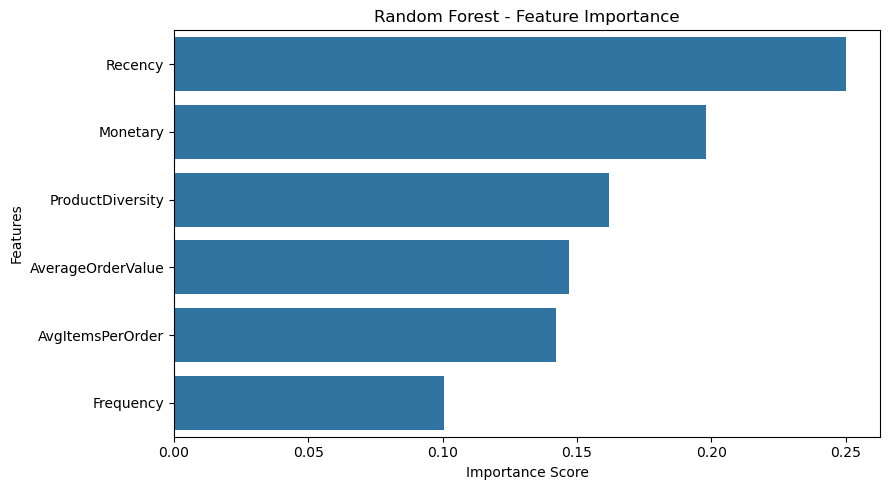

In [26]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title('Random Forest - Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

In [28]:
# Extract Logistic Regression coefficients

lr_model = models['Logistic Regression']

coefficients = pd.DataFrame({
    'Feature': feature_cols,
    'Coefficient': lr_model.named_steps['classifier'].coef_[0]
})

coefficients = coefficients.sort_values(
    by='Coefficient',
    ascending=False
)

coefficients

,Feature,Coefficient
0,Recency,1.145926
2,Monetary,0.497625
3,AverageOrderValue,0.319552
4,ProductDiversity,0.111756
5,AvgItemsPerOrder,-0.717102
1,Frequency,-0.888990


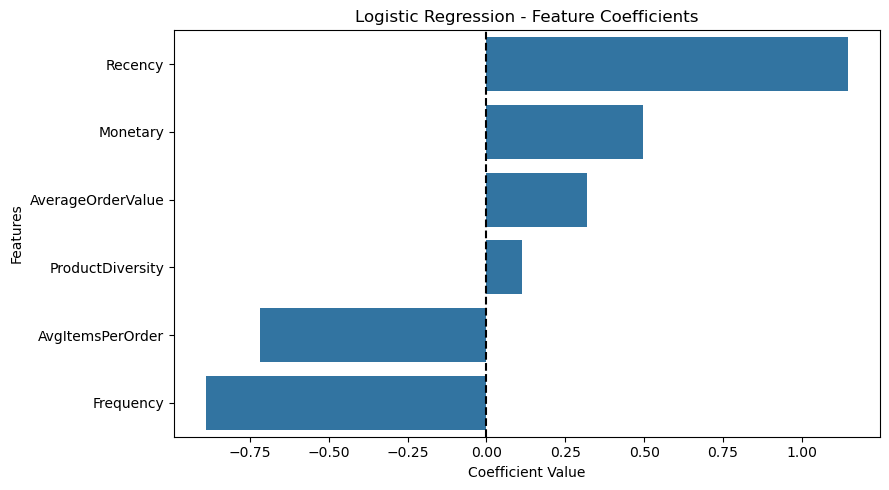

In [30]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=coefficients,
    x='Coefficient',
    y='Feature'
)

plt.axvline(0, color='black', linestyle='--')

plt.title('Logistic Regression - Feature Coefficients')
plt.xlabel('Coefficient Value')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

In [32]:
final_comparison = model_comparison.sort_values(
    by='F1-Score',
    ascending=False
).reset_index(drop=True)

final_comparison


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.735099,0.711905,0.652838,0.681093,0.796836
1,Logistic Regression,0.726585,0.697892,0.650655,0.673446,0.807583
2,SVM,0.725639,0.704878,0.631004,0.665899,0.788472
3,KNN,0.700095,0.664336,0.622271,0.642616,0.744097
4,Decision Tree,0.638600,0.584071,0.576419,0.580220,0.631281
5,Dummy Classifier,0.566698,0.000000,0.000000,0.000000,0.500000
